
# Startup Acquisition Prediction

## 1. Project Overview
This project analyses startup investment data to understand the factors associated with startup acquisition.

## 2. Problem Statement
Predicting whether a startup gets acquired or not using historical startup data.

## 3. Dataset Description
- Total records: 4,739
- Total columns: 22
- Target variable: `status`
- `1` = Acquired
- `0` = Not Acquired

## 4. Project Workflow
1. Data Loading
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Training
5. Model Evaluation
6. Results and Conclusion

In [1]:
pip install numpy pandas matplotlib scikit-learn



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error

In [3]:
dst = pd.read_csv('../datasets/data.csv')


In [4]:
dst.head()


,market,country_code,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
0,News,USA,2012,1750000.0,1,0.0,1750000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,Advertising,ARG,2007,4912393.0,1,4912393.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,Curated Web,USA,2010,2535000.0,2,0.0,15000.0,0.0,0.0,0.0,...,0.0,2520000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,Analytics,USA,2011,1250000.0,2,500000.0,750000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,Curated Web,USA,2009,50000.0,1,0.0,50000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [5]:
print('Shape:',dst.shape)     
print('Size :',dst.size)
print('Column Names :',dst.columns.tolist())
print('Number of columns :',len(dst.columns.tolist()))
print('numbers of rows :',dst.shape[0])
print()
print('Datatype of each column :')
print(dst.dtypes)      #datatypes of every column

Shape: (4757, 23)
Size : 109411
Column Names : ['market', 'country_code', 'founded_year', 'funding_total_usd', 'funding_rounds', 'unclassified_funding', 'seed', 'angel', 'equity_crowdfunding', 'convertible_note', 'debt_financing', 'grant', 'private_equity', 'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H', 'status']
Number of columns : 23
numbers of rows : 4757

Datatype of each column :
market                      str
country_code                str
founded_year              int64
funding_total_usd       float64
funding_rounds            int64
unclassified_funding    float64
seed                    float64
angel                   float64
equity_crowdfunding     float64
convertible_note        float64
debt_financing          float64
grant                   float64
private_equity          float64
product_crowdfunding    float64
round_A                 float64
round_B                 float64
round_C                 float64
rou

In [6]:
dst.info()

<class 'pandas.DataFrame'>
RangeIndex: 4757 entries, 0 to 4756
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   market                4757 non-null   str    
 1   country_code          4757 non-null   str    
 2   founded_year          4757 non-null   int64  
 3   funding_total_usd     4757 non-null   float64
 4   funding_rounds        4757 non-null   int64  
 5   unclassified_funding  4757 non-null   float64
 6   seed                  4757 non-null   float64
 7   angel                 4757 non-null   float64
 8   equity_crowdfunding   4757 non-null   float64
 9   convertible_note      4757 non-null   float64
 10  debt_financing        4757 non-null   float64
 11  grant                 4757 non-null   float64
 12  private_equity        4757 non-null   float64
 13  product_crowdfunding  4757 non-null   float64
 14  round_A               4757 non-null   float64
 15  round_B               4757 non-n

In [7]:
dst.isnull().sum()

market                  0
country_code            0
founded_year            0
funding_total_usd       0
funding_rounds          0
unclassified_funding    0
seed                    0
angel                   0
equity_crowdfunding     0
convertible_note        0
debt_financing          0
grant                   0
private_equity          0
product_crowdfunding    0
round_A                 0
round_B                 0
round_C                 0
round_D                 0
round_E                 0
round_F                 0
round_G                 0
round_H                 0
status                  0
dtype: int64

In [8]:
print("No. of duplicate rows" , dst.duplicated().sum())

No. of duplicate rows 18


In [9]:
print("Summary", dst.describe())

Summary        founded_year  funding_total_usd  funding_rounds  unclassified_funding  \
count   4757.000000       4.757000e+03     4757.000000          4.757000e+03   
mean    2005.897204       1.834339e+07        1.951860          4.613512e+06   
std        4.090614       9.819188e+07        1.354832          8.278538e+07   
min     1990.000000       1.000000e+03        1.000000          0.000000e+00   
25%     2004.000000       1.000000e+06        1.000000          0.000000e+00   
50%     2007.000000       5.000000e+06        1.000000          0.000000e+00   
75%     2009.000000       1.640000e+07        2.000000          1.507400e+06   
max     2014.000000       5.700000e+09       15.000000          5.620000e+09   

               seed         angel  equity_crowdfunding  convertible_note  \
count  4.757000e+03  4.757000e+03         4.757000e+03      4.757000e+03   
mean   1.934164e+05  8.648298e+04         1.671221e+03      1.022975e+04   
std    7.634434e+05  6.459516e+05         8

In [10]:
dst.describe()

,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,debt_financing,grant,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
count,4757.000000,4.757000e+03,4757.000000,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,...,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4757.0,4757.000000
mean,2005.897204,1.834339e+07,1.951860,4.613512e+06,1.934164e+05,8.648298e+04,1.671221e+03,1.022975e+04,1.553380e+06,3.765643e+04,...,5.675846e+02,2.112195e+06,3.119906e+06,2.370277e+06,1.322005e+06,5.142878e+05,2.097414e+05,2.848434e+04,0.0,0.619718
std,4.090614,9.819188e+07,1.354832,8.278538e+07,7.634434e+05,6.459516e+05,8.700127e+04,2.318734e+05,2.526918e+07,1.503298e+06,...,3.506712e+04,7.067711e+06,9.925746e+06,8.634016e+06,8.849721e+06,5.243109e+06,4.982326e+06,1.188800e+06,0.0,0.485507
min,1990.000000,1.000000e+03,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
25%,2004.000000,1.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
50%,2007.000000,5.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
75%,2009.000000,1.640000e+07,2.000000,1.507400e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
max,2014.000000,5.700000e+09,15.000000,5.620000e+09,2.500000e+07,3.000000e+07,5.500000e+06,1.352014e+07,1.200000e+09,9.980000e+07,...,2.400000e+06,2.250000e+08,3.500000e+08,2.000000e+08,2.500000e+08,2.200000e+08,2.860000e+08,6.300000e+07,0.0,1.000000


In [11]:
dst['status'].value_counts()

status
1    2948
0    1809
Name: count, dtype: int64

In [12]:
dst['status'].value_counts(normalize=True) * 100

status
1    61.971831
0    38.028169
Name: proportion, dtype: float64

In [13]:
dst.duplicated().sum()

np.int64(18)

In [24]:
duplicates = dst[dst.duplicated(keep=False)]

duplicates.sort_values(by=dst.columns.tolist())

,market,country_code,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
37,Biotechnology,USA,2007,3000000.0,1,3000000.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2852,Biotechnology,USA,2007,3000000.0,1,3000000.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
564,Curated Web,USA,2007,100000.0,1,0.0,0.0,100000.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1847,Curated Web,USA,2007,100000.0,1,0.0,0.0,100000.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1430,Curated Web,USA,2007,1700000.0,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1700000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1597,Curated Web,USA,2007,1700000.0,1,0.0,0.0,0.0,0.0,0.0,...,0.0,1700000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
870,Curated Web,USA,2007,2000000.0,1,0.0,0.0,0.0,0.0,0.0,...,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1106,Curated Web,USA,2007,2000000.0,1,0.0,0.0,0.0,0.0,0.0,...,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3897,Curated Web,USA,2007,2000000.0,1,0.0,0.0,0.0,0.0,0.0,...,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3651,Curated Web,USA,2007,2000000.0,1,0.0,0.0,2000000.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [27]:
dst = dst.drop_duplicates(keep='first')

In [28]:
print("Remaining duplicates:", dst.duplicated().sum())
print("Updated shape:", dst.shape)

Remaining duplicates: 0
Updated shape: (4739, 23)


In [14]:
dst.columns.tolist()

['market',
 'country_code',
 'founded_year',
 'funding_total_usd',
 'funding_rounds',
 'unclassified_funding',
 'seed',
 'angel',
 'equity_crowdfunding',
 'convertible_note',
 'debt_financing',
 'grant',
 'private_equity',
 'product_crowdfunding',
 'round_A',
 'round_B',
 'round_C',
 'round_D',
 'round_E',
 'round_F',
 'round_G',
 'round_H',
 'status']

In [15]:
dst.select_dtypes(include='number').columns.tolist()

['founded_year',
 'funding_total_usd',
 'funding_rounds',
 'unclassified_funding',
 'seed',
 'angel',
 'equity_crowdfunding',
 'convertible_note',
 'debt_financing',
 'grant',
 'private_equity',
 'product_crowdfunding',
 'round_A',
 'round_B',
 'round_C',
 'round_D',
 'round_E',
 'round_F',
 'round_G',
 'round_H',
 'status']

In [16]:
dst.select_dtypes(include='object').columns.tolist()

/var/folders/00/4mdl762x699f4cdgzb84006h0000gn/T/ipykernel_1893/836994305.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dst.select_dtypes(include='object').columns.tolist()


['market', 'country_code']

In [17]:
for col in dst.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(dst[col].nunique())


market:
377

country_code:
61


/var/folders/00/4mdl762x699f4cdgzb84006h0000gn/T/ipykernel_1893/2045612511.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in dst.select_dtypes(include='object').columns:


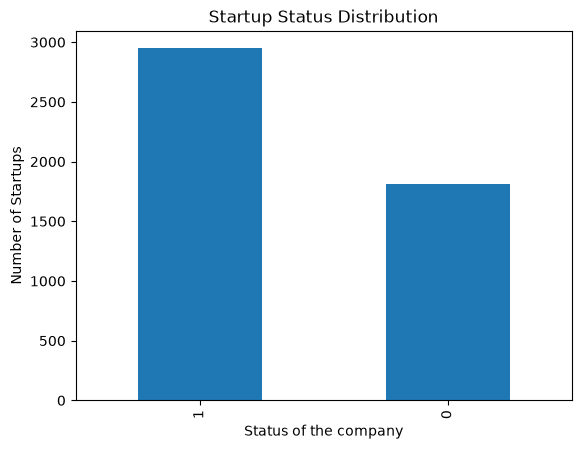

In [18]:
dst['status'].value_counts().plot(kind='bar')
plt.title('Startup Status Distribution')
plt.xlabel('Status of the company')
plt.ylabel('Number of Startups')
plt.show()

In [19]:
dst.describe()

,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,debt_financing,grant,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
count,4757.000000,4.757000e+03,4757.000000,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,...,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4757.0,4757.000000
mean,2005.897204,1.834339e+07,1.951860,4.613512e+06,1.934164e+05,8.648298e+04,1.671221e+03,1.022975e+04,1.553380e+06,3.765643e+04,...,5.675846e+02,2.112195e+06,3.119906e+06,2.370277e+06,1.322005e+06,5.142878e+05,2.097414e+05,2.848434e+04,0.0,0.619718
std,4.090614,9.819188e+07,1.354832,8.278538e+07,7.634434e+05,6.459516e+05,8.700127e+04,2.318734e+05,2.526918e+07,1.503298e+06,...,3.506712e+04,7.067711e+06,9.925746e+06,8.634016e+06,8.849721e+06,5.243109e+06,4.982326e+06,1.188800e+06,0.0,0.485507
min,1990.000000,1.000000e+03,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
25%,2004.000000,1.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
50%,2007.000000,5.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
75%,2009.000000,1.640000e+07,2.000000,1.507400e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
max,2014.000000,5.700000e+09,15.000000,5.620000e+09,2.500000e+07,3.000000e+07,5.500000e+06,1.352014e+07,1.200000e+09,9.980000e+07,...,2.400000e+06,2.250000e+08,3.500000e+08,2.000000e+08,2.500000e+08,2.200000e+08,2.860000e+08,6.300000e+07,0.0,1.000000


In [20]:
!pip install seaborn 
import seaborn as sns 


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


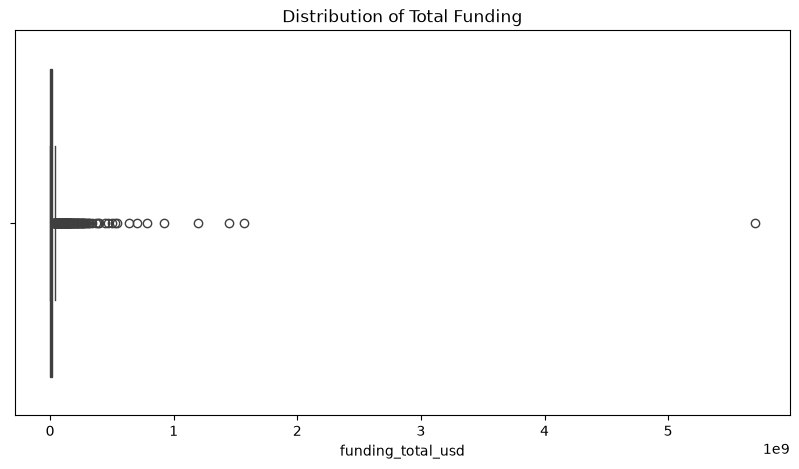

In [21]:
plt.figure(figsize=(10,5))
sns.boxplot(x=dst['funding_total_usd'])
plt.title("Distribution of Total Funding")
plt.show()

In [29]:
dst[['market', 'country_code']].nunique()

market          377
country_code     61
dtype: int64

In [30]:
print("Market — most common:")
print(dst['market'].value_counts().head(15))

print("\nCountry — most common:")
print(dst['country_code'].value_counts().head(15))

Market — most common:
market
Software               598
Biotechnology          296
Curated Web            286
Mobile                 265
Enterprise Software    213
Advertising            173
Games                  162
E-Commerce             132
Social Media           127
Clean Technology       115
Hardware + Software    113
Health Care            107
Semiconductors         106
Security                98
Web Hosting             94
Name: count, dtype: int64

Country — most common:
country_code
USA    3600
GBR     247
CAN     140
ISR      94
FRA      74
DEU      74
CHN      53
ESP      48
IND      34
IRL      29
SWE      23
NLD      21
SGP      20
RUS      19
AUS      19
Name: count, dtype: int64


In [31]:
print(dst['status'].value_counts())
print(dst['status'].unique())

status
1    2942
0    1797
Name: count, dtype: int64
[1 0]


In [33]:
print(dst.columns.tolist())

['market', 'country_code', 'founded_year', 'funding_total_usd', 'funding_rounds', 'unclassified_funding', 'seed', 'angel', 'equity_crowdfunding', 'convertible_note', 'debt_financing', 'grant', 'private_equity', 'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H', 'status']


In [34]:
funding_cols = [
    'funding_total_usd',
    'funding_rounds',
    'seed',
    'angel',
    'round_A',
    'round_B',
    'round_C',
    'round_D'
]

print(dst[funding_cols].corr().round(2))

                   funding_total_usd  funding_rounds  seed  angel  round_A  \
funding_total_usd               1.00            0.19 -0.01  -0.01     0.13   
funding_rounds                  0.19            1.00  0.03   0.02     0.15   
seed                           -0.01            0.03  1.00  -0.01     0.00   
angel                          -0.01            0.02 -0.01   1.00    -0.02   
round_A                         0.13            0.15  0.00  -0.02     1.00   
round_B                         0.22            0.29  0.01  -0.02     0.36   
round_C                         0.20            0.34 -0.03  -0.02     0.20   
round_D                         0.22            0.25 -0.03  -0.01    -0.00   

                   round_B  round_C  round_D  
funding_total_usd     0.22     0.20     0.22  
funding_rounds        0.29     0.34     0.25  
seed                  0.01    -0.03    -0.03  
angel                -0.02    -0.02    -0.01  
round_A               0.36     0.20    -0.00  
round_B        

In [35]:
funding_cols = [
    'funding_total_usd', 'funding_rounds',
    'seed', 'angel', 'round_A', 'round_B',
    'round_C', 'round_D'
]

print(dst[funding_cols + ['status']].corr()['status'].sort_values(ascending=False))

status               1.000000
funding_rounds       0.223550
round_C              0.134133
round_B              0.122685
round_A              0.082627
round_D              0.081758
funding_total_usd    0.073736
seed                 0.011041
angel               -0.013271
Name: status, dtype: float64


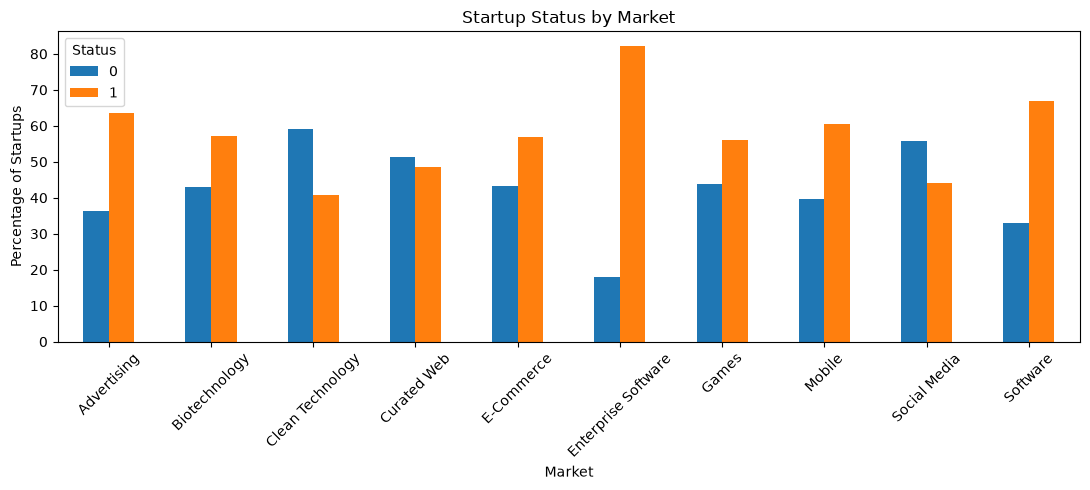

In [38]:
top_markets = dst['market'].value_counts().head(10).index

market_status = pd.crosstab(
    dst[dst['market'].isin(top_markets)]['market'],
    dst[dst['market'].isin(top_markets)]['status'],
    normalize='index'
) * 100

market_status.plot(kind='bar', figsize=(11, 5))

plt.ylabel('Percentage of Startups')
plt.xlabel('Market')
plt.title('Startup Status by Market')
plt.xticks(rotation=45)
plt.legend(title='Status')
plt.tight_layout()
plt.show()

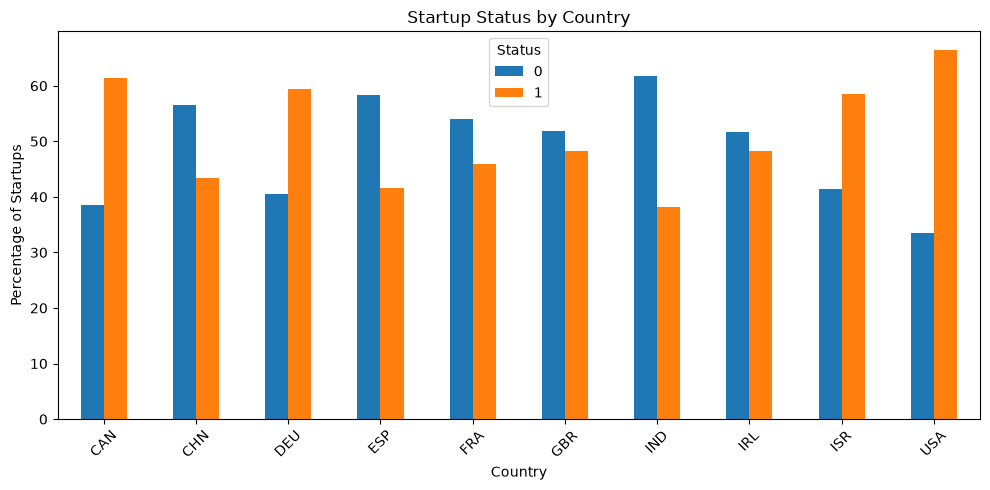

In [39]:
top_countries = dst['country_code'].value_counts().head(10).index

country_status = pd.crosstab(
    dst[dst['country_code'].isin(top_countries)]['country_code'],
    dst[dst['country_code'].isin(top_countries)]['status'],
    normalize='index'
) * 100

country_status.plot(kind='bar', figsize=(10, 5))

plt.title('Startup Status by Country')
plt.xlabel('Country')
plt.ylabel('Percentage of Startups')
plt.xticks(rotation=45)
plt.legend(title='Status')
plt.tight_layout()
plt.show()

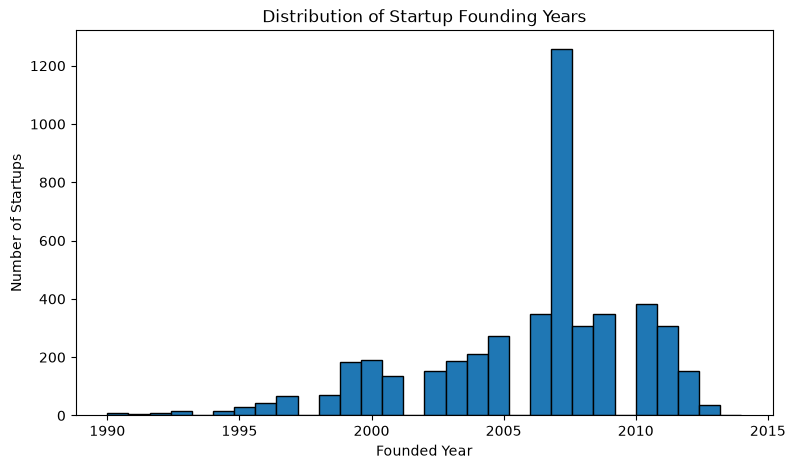

In [40]:
plt.figure(figsize=(9, 5))

plt.hist(dst['founded_year'].dropna(), bins=30, edgecolor='black')

plt.xlabel('Founded Year')
plt.ylabel('Number of Startups')
plt.title('Distribution of Startup Founding Years')

plt.show()

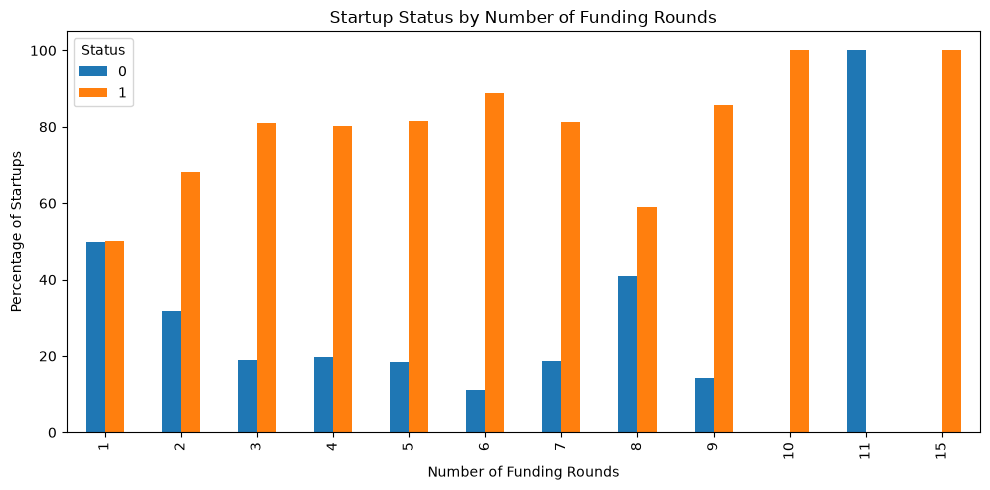

In [42]:
funding_status = pd.crosstab(
    dst['funding_rounds'],
    dst['status'],
    normalize='index'
) * 100

funding_status.plot(kind='bar', figsize=(10, 5))

plt.title('Startup Status by Number of Funding Rounds')
plt.xlabel('Number of Funding Rounds')
plt.ylabel('Percentage of Startups')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

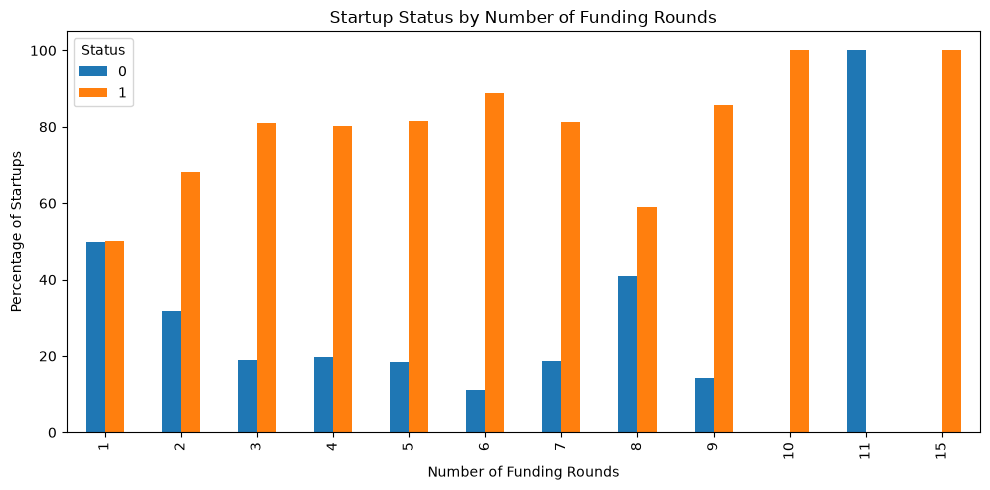

In [44]:
dst.groupby('status')[
    ['founded_year', 'funding_total_usd', 'funding_rounds']
].agg(['mean', 'median', 'std']).round(2)

founded_year               funding_total_usd                           \
               mean  median   std              mean     median           std   
status                                                                         
0           2007.15  2007.0  3.34        9123196.77  1100000.0  4.589644e+07   
1           2005.12  2007.0  4.32       24071760.58  8750000.0  1.192440e+08   

       funding_rounds               
                 mean median   std  
status                              
0                1.57    1.0  1.09  
1                2.19    2.0  1.44